In [1]:
import os, datetime as dt
import ee
import geemap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT = "fall-foliage-project"      # your Earth Engine / Cloud project ID
ee.Initialize(project=PROJECT)
OUT_DIR, FIG_DIR = "data", "figures"
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

UNIV_BUFFER = 40_000          # 40 km radius around each site
FOREST_THRESHOLD = 0.5        # a 500 m pixel counts as forest if >= 50% of its 30 m NLCD pixels are forest
PHENO_YEARS = range(2001, 2026)   # years that don't exist in a product are skipped automatically
WX_YEARS = range(2001, 2027)      # gridMET includes 2026
WX_START, WX_END = "07-01", "12-01"

locations = {
    "Raleigh":    [-78.69649427302112, 35.7664191909458],
    "Boone":      [-81.68516978460896, 36.21834246106182],
    "Asheville":  [-82.55831963941482, 35.633546529345516],
    "Charleston": [-79.9294956284804,  32.796133071541156],
    "Shenandoah": [-78.40685152551191, 38.499092552797826],
}
REGION_ORDER = list(locations)   # fixed order -> fixed colors / facet order everywhere

In [2]:
ecoregions = ee.FeatureCollection("EPA/Ecoregions/2013/L3")

feats = []
for name, coords in locations.items():
    center = ee.Geometry.Point(coords)
    home_eco = ee.Feature(ecoregions.filterBounds(center).first())
    clipped = center.buffer(UNIV_BUFFER).intersection(home_eco.geometry(), ee.ErrorMargin(100))
    feats.append(ee.Feature(clipped, {"name": name, "ecoregion": home_eco.get("us_l3name")}))
study_regions = ee.FeatureCollection(feats)

nlcd = ee.Image("USGS/NLCD_RELEASES/2021_REL/NLCD/2021").select("landcover")
forest_mask = nlcd.eq(41).Or(nlcd.eq(43))       # deciduous + mixed forest (30 m)


def forest_on_grid(proj):
    # Fraction of each coarse pixel that is forest, thresholded -> 1/0 on the product's own grid
    return (forest_mask.unmask(0)
            .reduceResolution(reducer=ee.Reducer.mean(), maxPixels=1024)
            .reproject(crs=proj)
            .gte(FOREST_THRESHOLD))


def fc_to_df(fc):
    # FeatureCollection -> DataFrame without geometries (avoids the geemap.ee_to_df pandas bug)
    fc = fc.map(lambda f: ee.Feature(None, f.toDictionary()))
    return pd.DataFrame([f["properties"] for f in fc.getInfo()["features"]])

In [3]:
MODIS = dict(
    id="MODIS/061/MCD12Q2",
    bands={"MidGreenup_1": "mid_greenup", "Senescence_1": "senescence",
           "MidGreendown_1": "mid_greendown", "Dormancy_1": "dormancy"},
    qa=lambda img: img.select("QA_Overall_1").lte(1),
)
VIIRS = dict(
    id="NASA/VIIRS/002/VNP22Q2",
    bands={"Date_Mid_Greenup_Phase_1": "mid_greenup",
           "Onset_Greenness_Decrease_1": "senescence",
           "Date_Mid_Senescence_Phase_1": "mid_greendown",
           "Onset_Greenness_Minimum_1": "dormancy"},
    qa=lambda img: (img.select("GLSP_QC_1").bitwiseAnd(7).lte(1)                     # bits 0-2: good / other quality
                    .And(img.select("GLSP_QC_1").rightShift(5).bitwiseAnd(7).eq(1))),  # bits 5-7: land
)
COMMON = ["mid_greenup", "senescence", "mid_greendown", "dormancy"]


def year_image(col, year):
    return ee.Image(col.filter(ee.Filter.calendarRange(year, year, "year")).first())


def detect_encoding(img, band, year):
    # Decide how dates are stored by looking at the median raw value over the study area
    v = img.select(band).reduceRegion(ee.Reducer.median(), study_regions.geometry().bounds(),
                                      scale=5000, bestEffort=True).get(band).getInfo()
    if v is None:
        raise ValueError(f"No valid {band} pixels in {year} - try another year for detection")
    if v <= 800:
        enc = "day_of_year"
    elif v > 10_000:
        enc = "days_since_1970"
    else:
        enc = "days_since_2000"
    print(f"  raw median {band} ({year}) = {v:.0f}  ->  encoding: {enc}")
    return enc


def doy_offset(enc, year):
    # value to subtract from the raw date so it becomes day-of-year (Jan 1 = 1)
    if enc == "day_of_year":
        return 0
    epoch = dt.date(1970, 1, 1) if enc == "days_since_1970" else dt.date(2000, 1, 1)
    return (dt.date(year, 1, 1) - epoch).days - 1


def pull_phenology(spec, product, years=PHENO_YEARS):
    col = ee.ImageCollection(spec["id"])
    available = set(col.aggregate_array("system:time_start")
                       .map(lambda t: ee.Date(t).get("year")).getInfo())
    years = [y for y in years if y in available]
    print(f"{product}: years available {years[0]}-{years[-1]} ({len(years)} years)")

    names = year_image(col, years[0]).bandNames().getInfo()
    missing = [b for b in spec["bands"] if b not in names]
    if missing:
        raise KeyError(f"{product} is missing bands {missing}. Available: {names}")

    src = list(spec["bands"])
    enc = detect_encoding(year_image(col, years[-1]), src[2], years[-1])

    reducer = (ee.Reducer.percentile([25, 50, 75])
               .combine(ee.Reducer.count(), sharedInputs=True))
    rows = []
    for year in years:
        img = year_image(col, year)
        proj = img.select(src[0]).projection()
        forest = forest_on_grid(proj)
        doy = (img.select(src, COMMON)
               .subtract(doy_offset(enc, year))
               .updateMask(forest)
               .updateMask(spec["qa"](img)))
        stack = doy.addBands(ee.Image.constant(1).rename("forest_px")
                             .reproject(proj).updateMask(forest))
        fc = stack.reduceRegions(collection=study_regions, reducer=reducer,
                                 crs=proj, scale=proj.nominalScale().getInfo(), tileScale=8)
        df = fc_to_df(fc)
        df["year"], df["product"] = year, product
        rows.append(df)
        print(f"  {year} done", end="\r")
    print()
    out = pd.concat(rows, ignore_index=True)
    keep = (["name", "ecoregion", "year", "product", "forest_px_count"]
            + [f"{b}_{s}" for b in COMMON for s in ("p25", "p50", "p75", "count")])
    return out[[c for c in keep if c in out.columns]]

In [4]:
modis_df = pull_phenology(MODIS, "MODIS")
viirs_df = pull_phenology(VIIRS, "VIIRS")

phen = pd.concat([modis_df, viirs_df], ignore_index=True)
phen["qa_retention"] = phen["mid_greendown_count"] / phen["forest_px_count"]
phen.to_csv(f"{OUT_DIR}/phenology_regions.csv", index=False)

# Sanity check: fall mid-greendown should land roughly in Sep-Nov (DOY ~245-335)
odd = phen[(phen["mid_greendown_p50"] < 230) | (phen["mid_greendown_p50"] > 350)]
print(f"{len(phen)} rows saved. Rows with implausible greendown dates: {len(odd)}")
if len(odd):
    display(odd[["name", "year", "product", "mid_greendown_p50", "mid_greendown_count"]])
phen.head()

MODIS: years available 2001-2025 (25 years)
  raw median MidGreendown_1 (2025) = 20361  ->  encoding: days_since_1970
  2025 done
VIIRS: years available 2013-2025 (13 years)
  raw median Date_Mid_Senescence_Phase_1 (2025) = 9416  ->  encoding: days_since_2000
  2025 done
190 rows saved. Rows with implausible greendown dates: 0


,name,ecoregion,year,product,forest_px_count,mid_greenup_p25,mid_greenup_p50,mid_greenup_p75,mid_greenup_count,senescence_p25,...,senescence_count,mid_greendown_p25,mid_greendown_p50,mid_greendown_p75,mid_greendown_count,dormancy_p25,dormancy_p50,dormancy_p75,dormancy_count,qa_retention
0,Raleigh,Piedmont,2001,MODIS,2905,108.242882,110.271066,113.550075,2904,208.000000,...,2904,278.000000,281.542748,285.000000,2904,317.146528,319.696408,323.000000,2904,0.999656
1,Boone,Blue Ridge,2001,MODIS,18705,118.260758,128.392424,132.000000,18705,218.530753,...,18705,272.000000,275.354009,278.230209,18705,301.483301,304.000000,308.460499,18705,1.000000
2,Asheville,Blue Ridge,2001,MODIS,17272,119.370552,124.000000,129.000000,17272,219.281195,...,17272,274.000000,278.252745,280.265236,17272,304.306716,307.463234,310.000000,17272,1.000000
3,Charleston,Southern Coastal Plain,2001,MODIS,1,105.000000,105.000000,105.000000,1,227.000000,...,1,284.000000,284.000000,284.000000,1,344.000000,344.000000,344.000000,1,1.000000
4,Shenandoah,Blue Ridge,2001,MODIS,5774,118.402508,123.350537,128.000000,5774,226.000000,...,5774,279.438308,283.411840,287.410629,5774,308.022861,312.000000,316.407865,5774,1.000000


In [16]:
GRIDMET_BANDS = ["tmmn", "tmmx", "pr", "srad", "vpd"]


def pull_daily(col_id, bands, years, scale):
    base = ee.ImageCollection(col_id).select(bands)
    out = []
    for year in years:
        col = base.filterDate(f"{year}-{WX_START}", f"{year}-{WX_END}")

        def per_image(img):
            stats = img.reduceRegions(collection=study_regions, reducer=ee.Reducer.mean(), scale=scale)
            return stats.map(lambda f: ee.Feature(None, f.toDictionary())
                             .set("date", img.date().format("YYYY-MM-dd")))

        fc = col.map(per_image).flatten()
        out.append(pd.DataFrame([f["properties"] for f in fc.getInfo()["features"]]))
        print(f"  {col_id.split('/')[-1]} {year} done", end="\r")
    print()
    df = pd.concat(out, ignore_index=True)
    if len(bands) == 1 and "mean" in df.columns:
        df = df.rename(columns={"mean": bands[0]})
    df = df[["name", "date"] + [b for b in bands if b in df.columns]]
    df["date"] = pd.to_datetime(df["date"])
    return df


wx = pull_daily("IDAHO_EPSCOR/GRIDMET", GRIDMET_BANDS, WX_YEARS, scale=4638.3)
wx = wx.rename(columns={"tmmn": "tmin", "tmmx": "tmax"})
wx["tmin"] -= 273.15                   # Kelvin -> °C
wx["tmax"] -= 273.15
wx["tmean"] = (wx["tmin"] + wx["tmax"]) / 2
wx.to_csv(f"{OUT_DIR}/weather_daily.csv", index=False)
print(f"weather_daily.csv: {len(wx):,} rows, {wx['date'].min().date()} -> {wx['date'].max().date()}")

try:
    pdsi = pull_daily("GRIDMET/DROUGHT", ["pdsi"], WX_YEARS, scale=4638.3)
    pdsi.to_csv(f"{OUT_DIR}/pdsi.csv", index=False)
    print(f"pdsi.csv: {len(pdsi):,} rows")
except Exception as e:
    print("PDSI pull failed (weather pull is unaffected):", e)

  GRIDMET 2026 done
weather_daily.csv: 19,795 rows, 2001-07-01 -> 2026-11-11
  DROUGHT 2026 done
pdsi.csv: 3,910 rows


In [6]:
MAP_YEAR = 2019
col = ee.ImageCollection(MODIS["id"])
img = year_image(col, MAP_YEAR)
proj = img.select("MidGreendown_1").projection()
greendown = (img.select("MidGreendown_1")
             .subtract(doy_offset("days_since_1970", MAP_YEAR))
             .updateMask(MODIS["qa"](img))
             .updateMask(forest_on_grid(proj)))

vis = {"min": 270, "max": 330, "palette": ["fff7bc", "fec44f", "ec7014", "993404", "4a1a04"]}
m = geemap.Map()
m.add_basemap("SATELLITE")
m.addLayer(greendown.clip(study_regions.geometry().bounds().buffer(50_000)), vis,
           f"MODIS mid-greendown DOY {MAP_YEAR}")
m.addLayer(study_regions.style(color="ffffff", fillColor="00000000", width=2), {}, "Study regions")
m.add_colorbar(vis, label=f"Mid-greendown, day of year ({MAP_YEAR})  ·  280 ≈ Oct 7, 305 = Nov 1")
m.centerObject(study_regions, 6)
m

Map(center=[35.78771285214042, -80.8144217567992], controls=(WidgetControl(options=['position', 'transparent_b…

In [7]:
phen = pd.read_csv(f"{OUT_DIR}/phenology_regions.csv")
wx = pd.read_csv(f"{OUT_DIR}/weather_daily.csv", parse_dates=["date"])
pdsi = (pd.read_csv(f"{OUT_DIR}/pdsi.csv", parse_dates=["date"])
        if os.path.exists(f"{OUT_DIR}/pdsi.csv") else None)

REGION_ORDER = [r for r in REGION_ORDER if r in set(phen["name"])]
PRODUCT_COLORS = {"MODIS": "#2a78d6", "VIIRS": "#eb6834"}           # blue / orange
REGION_COLORS = dict(zip(REGION_ORDER, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "legend.frameon": False, "lines.linewidth": 2,
})

# Day-of-year <-> month ticks (non-leap year; ±1 day in leap years is fine for axis labels)
MONTH_DOY = {"Jul 1": 182, "Aug 1": 213, "Sep 1": 244, "Oct 1": 274, "Nov 1": 305, "Dec 1": 335}
def month_axis(ax, axis="y", lo=None, hi=None):
    ticks = {k: v for k, v in MONTH_DOY.items()
             if (lo is None or v >= lo) and (hi is None or v <= hi)}
    (ax.set_yticks if axis == "y" else ax.set_xticks)(list(ticks.values()))
    (ax.set_yticklabels if axis == "y" else ax.set_xticklabels)(list(ticks.keys()))

def save(fig, name):
    fig.savefig(f"{FIG_DIR}/{name}.png")
    plt.show()

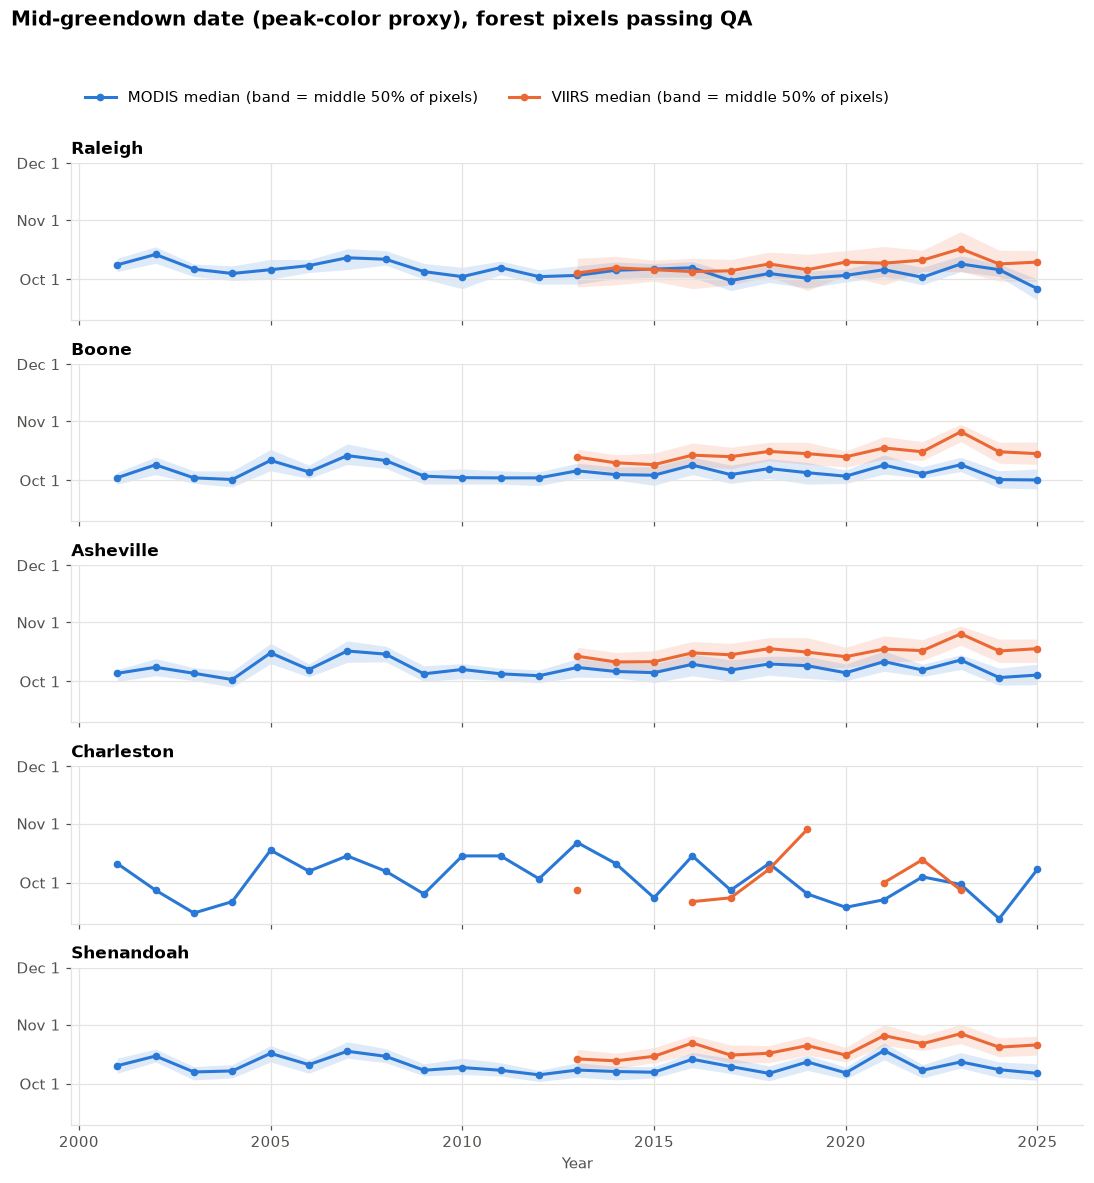

In [8]:
fig, axes = plt.subplots(len(REGION_ORDER), 1, figsize=(10, 2.1 * len(REGION_ORDER)),
                         sharex=True, sharey=True)
for ax, region in zip(np.atleast_1d(axes), REGION_ORDER):
    for product, color in PRODUCT_COLORS.items():
        d = phen[(phen["name"] == region) & (phen["product"] == product)].sort_values("year")
        if d.empty:
            continue
        ax.fill_between(d["year"], d["mid_greendown_p25"], d["mid_greendown_p75"],
                        color=color, alpha=0.15, linewidth=0)
        ax.plot(d["year"], d["mid_greendown_p50"], color=color, marker="o", markersize=4,
                label=f"{product} median (band = middle 50% of pixels)")
    ax.set_title(region, loc="left")
    month_axis(ax, "y", 250, 340)
axes[0].legend(loc="upper left", bbox_to_anchor=(0, 1.55), ncol=2)
axes[-1].set_xlabel("Year")
fig.suptitle("Mid-greendown date (peak-color proxy), forest pixels passing QA", x=0.01, ha="left",
             y=1.02, fontsize=13, fontweight="bold")
fig.tight_layout()
save(fig, "fig1_greendown_timeseries")

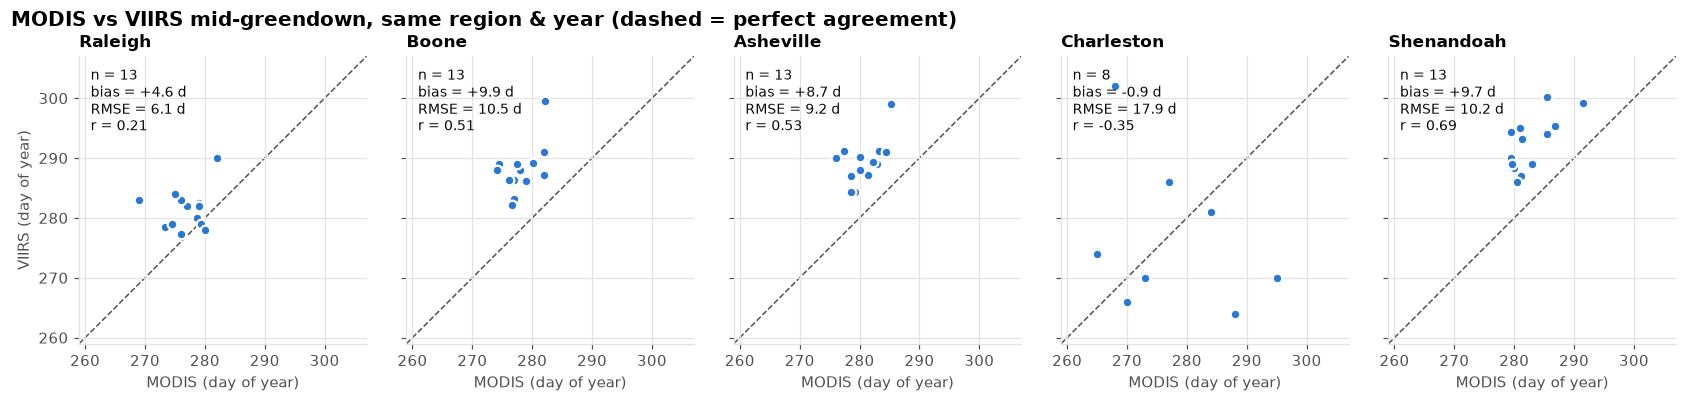

,name,n,bias_days,rmse_days,r
0,Raleigh,13,4.56,6.14,0.21
1,Boone,13,9.93,10.52,0.51
2,Asheville,13,8.67,9.21,0.53
3,Charleston,8,-0.88,17.86,-0.35
4,Shenandoah,13,9.70,10.21,0.69


In [9]:
wide = (phen.pivot_table(index=["name", "year"], columns="product", values="mid_greendown_p50")
            .dropna().reset_index())
n = len(REGION_ORDER)
fig, axes = plt.subplots(1, n, figsize=(3.1 * n, 3.4), sharex=True, sharey=True)
lo, hi = wide[["MODIS", "VIIRS"]].min().min() - 5, wide[["MODIS", "VIIRS"]].max().max() + 5
agree = []
for ax, region in zip(np.atleast_1d(axes), REGION_ORDER):
    d = wide[wide["name"] == region]
    ax.plot([lo, hi], [lo, hi], color=INK2, linewidth=1, linestyle="--", zorder=1)
    ax.scatter(d["MODIS"], d["VIIRS"], s=40, color=PRODUCT_COLORS["MODIS"],
               edgecolor="white", linewidth=1.5, zorder=2)
    if len(d) >= 3:
        diff = d["VIIRS"] - d["MODIS"]
        r = np.corrcoef(d["MODIS"], d["VIIRS"])[0, 1]
        stats = dict(name=region, n=len(d), bias_days=diff.mean(),
                     rmse_days=np.sqrt((diff ** 2).mean()), r=r)
        agree.append(stats)
        ax.text(0.04, 0.96, f"n = {len(d)}\nbias = {stats['bias_days']:+.1f} d\n"
                            f"RMSE = {stats['rmse_days']:.1f} d\nr = {r:.2f}",
                transform=ax.transAxes, va="top", fontsize=9, color=INK)
    ax.set_title(region, loc="left")
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect("equal")
    ax.set_xlabel("MODIS (day of year)")
np.atleast_1d(axes)[0].set_ylabel("VIIRS (day of year)")
fig.suptitle("MODIS vs VIIRS mid-greendown, same region & year (dashed = perfect agreement)",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
save(fig, "fig2_modis_vs_viirs")
agreement = pd.DataFrame(agree).round(2)
agreement

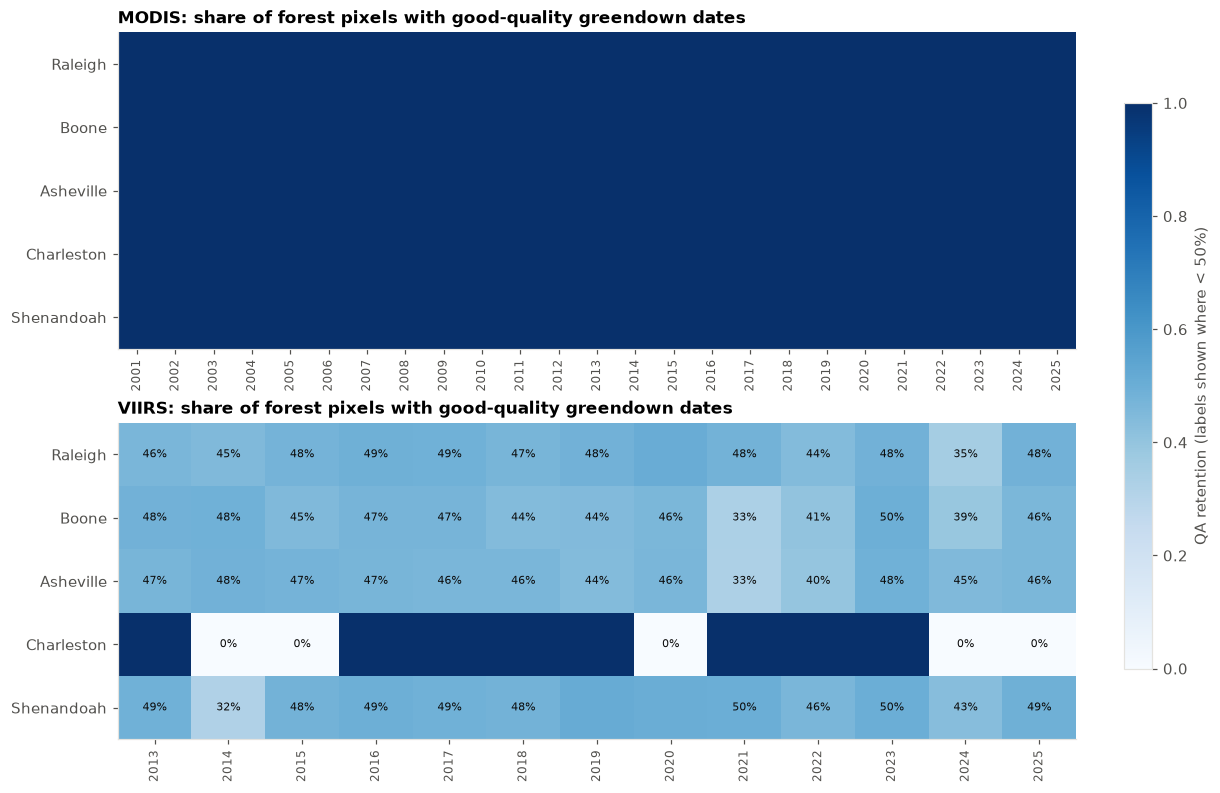

Median good-quality forest pixels per region-year:


product,MODIS,VIIRS
name,,
Raleigh,2904.0,1386.0
Boone,18705.0,8575.0
Asheville,17272.0,8021.0
Charleston,1.0,1.0
Shenandoah,5774.0,2812.0


In [10]:
products = [p for p in PRODUCT_COLORS if p in set(phen["product"])]
fig, axes = plt.subplots(len(products), 1, figsize=(11, 1.6 + 0.55 * len(REGION_ORDER) * len(products)),
                         squeeze=False, layout="constrained")
for ax, product in zip(axes[:, 0], products):
    grid = (phen[phen["product"] == product]
            .pivot_table(index="name", columns="year", values="qa_retention")
            .reindex(REGION_ORDER))
    im = ax.imshow(grid.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    ax.set_yticks(range(len(grid.index)), grid.index)
    ax.set_xticks(range(len(grid.columns)), grid.columns, rotation=90, fontsize=8)
    ax.grid(False)
    ax.set_title(f"{product}: share of forest pixels with good-quality greendown dates", loc="left")
    for (i, j), v in np.ndenumerate(grid.values):          # flag weak region-years in text, not just color
        if np.isfinite(v) and v < 0.5:
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=7, color=INK)
fig.colorbar(im, ax=axes[:, 0], label="QA retention (labels shown where < 50%)", shrink=0.8)
save(fig, "fig3_qa_retention")

print("Median good-quality forest pixels per region-year:")
phen.pivot_table(index="name", columns="product", values="mid_greendown_count", aggfunc="median") \
    .reindex(REGION_ORDER).round(0)

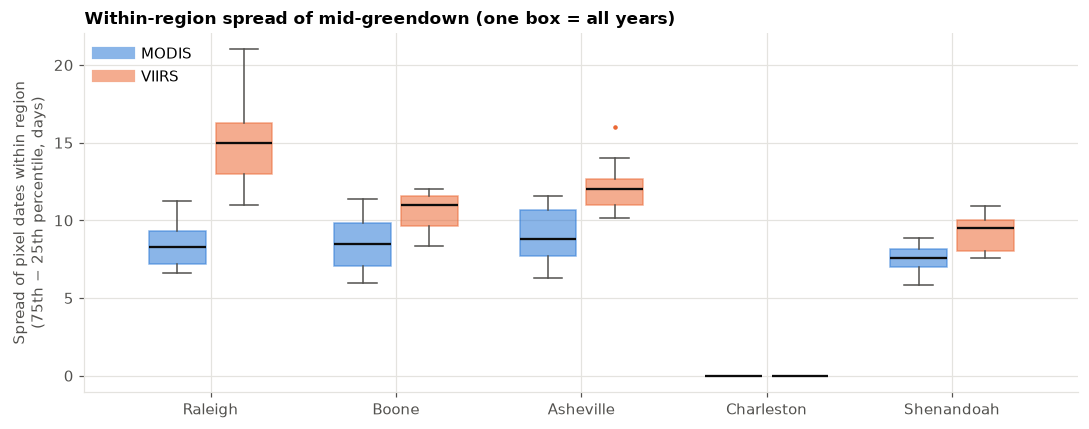

In [11]:
phen["iqr_days"] = phen["mid_greendown_p75"] - phen["mid_greendown_p25"]
fig, ax = plt.subplots(figsize=(10, 4))
width = 0.36
for k, (product, color) in enumerate(PRODUCT_COLORS.items()):
    data = [phen[(phen["name"] == r) & (phen["product"] == product)]["iqr_days"].dropna()
            for r in REGION_ORDER]
    pos = np.arange(len(REGION_ORDER)) + (k - 0.5) * width
    bp = ax.boxplot(data, positions=pos, widths=width * 0.85, patch_artist=True,
                    medianprops=dict(color=INK, linewidth=1.5),
                    whiskerprops=dict(color=INK2), capprops=dict(color=INK2),
                    flierprops=dict(marker="o", markersize=4, markerfacecolor=color,
                                    markeredgecolor="white"))
    for box in bp["boxes"]:
        box.set(facecolor=color, alpha=0.55, edgecolor=color)
    ax.plot([], [], color=color, linewidth=8, alpha=0.55, label=product)
ax.set_xticks(range(len(REGION_ORDER)), REGION_ORDER)
ax.set_ylabel("Spread of pixel dates within region\n(75th − 25th percentile, days)")
ax.legend(loc="upper left")
ax.set_title("Within-region spread of mid-greendown (one box = all years)", loc="left")
fig.tight_layout()
save(fig, "fig4_within_region_spread")

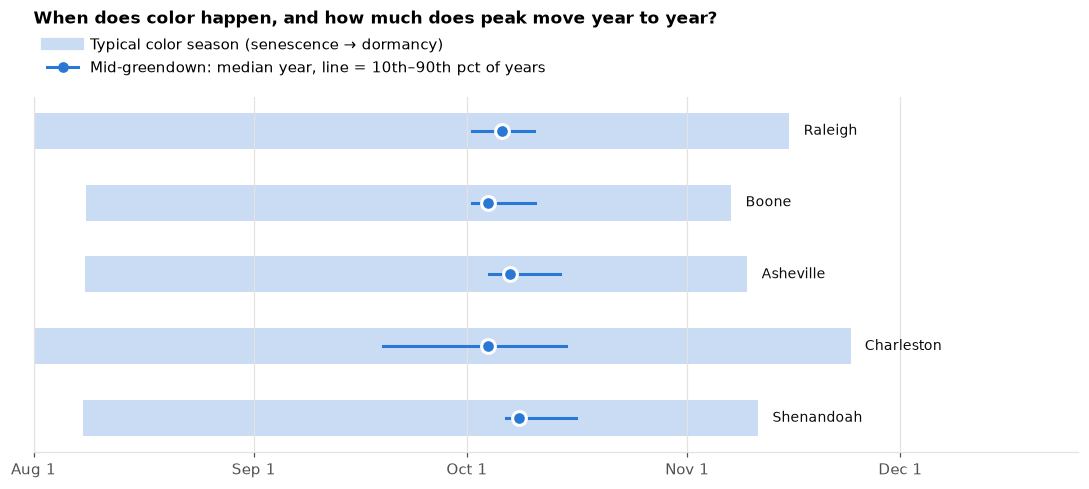

In [12]:
mod = phen[phen["product"] == "MODIS"]
fig, ax = plt.subplots(figsize=(10, 0.8 + 0.75 * len(REGION_ORDER)))
for i, region in enumerate(REGION_ORDER[::-1]):
    d = mod[mod["name"] == region]
    if d.empty:
        continue
    sen, dor = d["senescence_p50"].median(), d["dormancy_p50"].median()
    g = d["mid_greendown_p50"]
    ax.barh(i, dor - sen, left=sen, height=0.5, color="#c9dcf3", edgecolor="none")
    ax.plot([g.quantile(0.1), g.quantile(0.9)], [i, i], color="#2a78d6", linewidth=2)
    ax.plot(g.median(), i, "o", color="#2a78d6", markersize=9, markeredgecolor="white",
            markeredgewidth=2)
    ax.text(dor + 2, i, f"{region}", va="center", fontsize=9, color=INK)
ax.set_yticks([])
month_axis(ax, "x", 213, 335)
ax.set_xlim(213, 360)
ax.plot([], [], color="#c9dcf3", linewidth=8, label="Typical color season (senescence → dormancy)")
ax.plot([], [], "o-", color="#2a78d6", label="Mid-greendown: median year, line = 10th–90th pct of years")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.02), ncol=1)
ax.set_title("When does color happen, and how much does peak move year to year?", loc="left", pad=48)
fig.tight_layout()
save(fig, "fig5_color_season")

In [13]:
wx["year"] = wx["date"].dt.year
days = wx.groupby(["name", "year"])["date"].nunique().unstack("name").reindex(columns=REGION_ORDER)
expected = 153   # Jul 1 -> Nov 30
gaps = days[(days < expected).any(axis=1)]
print(f"Region-years with fewer than {expected} days (2026 will be short — the season isn't over):")
display(gaps)
print("Missing values per variable:")
wx[["tmin", "tmax", "pr", "srad", "vpd"]].isna().sum()

Region-years with fewer than 153 days (2026 will be short — the season isn't over):


name,Raleigh,Boone,Asheville,Charleston,Shenandoah
year,,,,,
2026,134,134,134,134,134


Missing values per variable:


tmin    0
tmax    0
pr      0
srad    0
vpd     0
dtype: int64

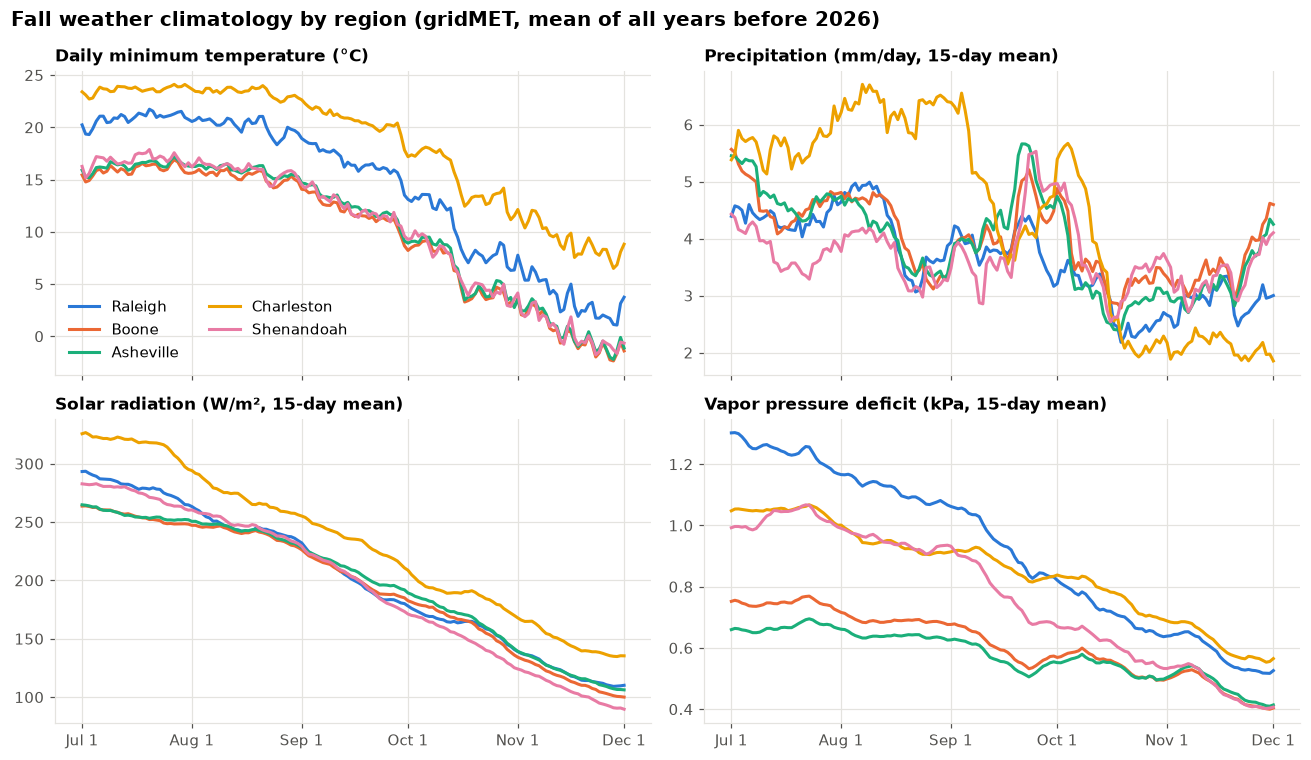

In [14]:
wx["doy"] = wx["date"].dt.dayofyear
clim = wx[wx["year"] < 2026].groupby(["name", "doy"])[["tmin", "tmean", "pr", "srad", "vpd"]].mean()
panels = [("tmin", "Daily minimum temperature (°C)", False),
          ("pr", "Precipitation (mm/day, 15-day mean)", True),
          ("srad", "Solar radiation (W/m², 15-day mean)", True),
          ("vpd", "Vapor pressure deficit (kPa, 15-day mean)", True)]
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for ax, (var, label, smooth) in zip(axes.flat, panels):
    for region in REGION_ORDER:
        s = clim.loc[region, var]
        if smooth:
            s = s.rolling(15, center=True, min_periods=5).mean()
        ax.plot(s.index, s.values, color=REGION_COLORS[region], label=region)
    ax.set_title(label, loc="left")
    month_axis(ax, "x", 182, 335)
axes[0, 0].legend(loc="lower left", ncol=2)
fig.suptitle("Fall weather climatology by region (gridMET, mean of all years before 2026)",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
save(fig, "fig6_weather_climatology")

In [19]:
wx["year"] = wx["date"].dt.year

def window(df, start, end):
    md = df["date"].dt.strftime("%m-%d")
    return df[(md >= start) & (md <= end)]

feat = pd.DataFrame({
    "tmin_SepOct":  window(wx, "09-01", "10-31").groupby(["name", "year"])["tmin"].mean(),
    "cold_dd_Sep1_Oct15": window(wx, "09-01", "10-15").assign(
        cdd=lambda d: (20 - d["tmean"]).clip(lower=0)).groupby(["name", "year"])["cdd"].sum(),
    "precip_AugSep": window(wx, "08-01", "09-30").groupby(["name", "year"])["pr"].sum(),
    "srad_SepOct":  window(wx, "09-01", "10-31").groupby(["name", "year"])["srad"].mean(),
    "vpd_AugSep":   window(wx, "08-01", "09-30").groupby(["name", "year"])["vpd"].mean(),
})
if pdsi is not None:
    pdsi["year"] = pdsi["date"].dt.year
    feat["pdsi_AugSep"] = window(pdsi, "08-01", "09-30").groupby(["name", "year"])["pdsi"].mean()
feat = feat.reset_index()
feat.to_csv(f"{OUT_DIR}/weather_features.csv", index=False)
feat.head()

,name,year,tmin_SepOct,cold_dd_Sep1_Oct15,precip_AugSep,srad_SepOct,vpd_AugSep,pdsi_AugSep
0,Asheville,2001,6.332893,230.937374,189.717095,190.772192,0.509480,-2.208038
1,Asheville,2002,11.517329,88.469720,217.544567,169.563544,0.670944,-3.976240
2,Asheville,2003,7.742068,211.507382,263.648028,188.677631,0.471567,3.980610
3,Asheville,2004,10.721398,150.695747,549.843636,187.164983,0.520185,1.331001
4,Asheville,2005,9.524890,83.314375,194.850240,197.078056,0.624386,3.495002


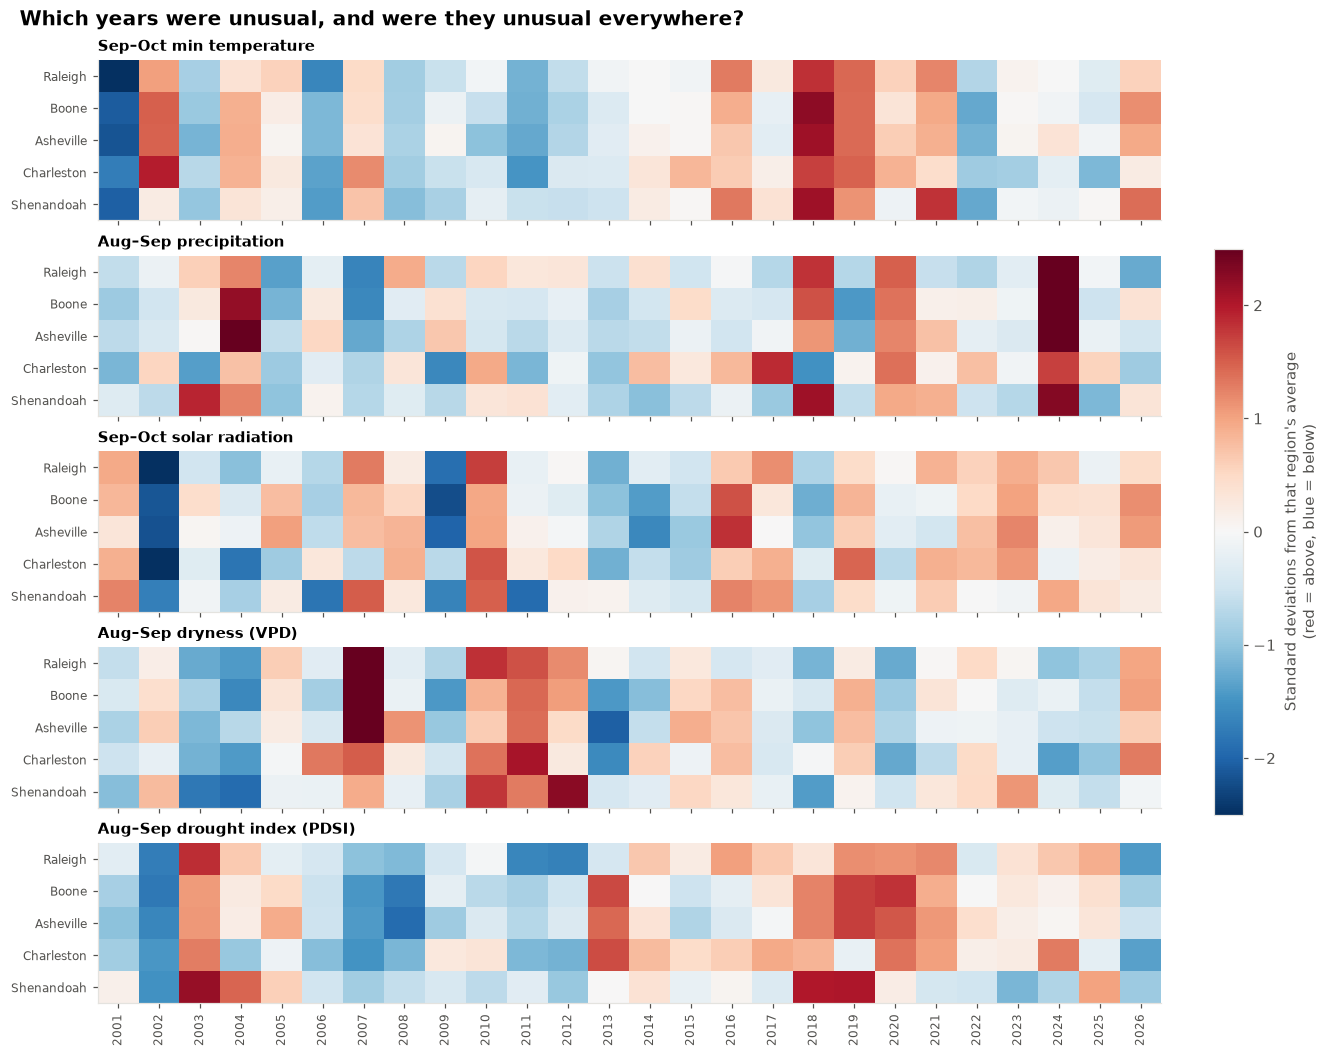

In [20]:
vars7 = [c for c in ["tmin_SepOct", "precip_AugSep", "srad_SepOct", "vpd_AugSep", "pdsi_AugSep"]
         if c in feat.columns]
titles = {"tmin_SepOct": "Sep–Oct min temperature", "precip_AugSep": "Aug–Sep precipitation",
          "srad_SepOct": "Sep–Oct solar radiation", "vpd_AugSep": "Aug–Sep dryness (VPD)",
          "pdsi_AugSep": "Aug–Sep drought index (PDSI)"}
fig, axes = plt.subplots(len(vars7), 1, figsize=(12, 1.5 + 1.6 * len(vars7)), sharex=True,
                         layout="constrained")
for ax, var in zip(np.atleast_1d(axes), vars7):
    z = (feat.pivot_table(index="name", columns="year", values=var).reindex(REGION_ORDER))
    z = z.sub(z.mean(axis=1), axis=0).div(z.std(axis=1), axis=0)
    im = ax.imshow(z.values, cmap="RdBu_r", vmin=-2.5, vmax=2.5, aspect="auto")
    ax.set_yticks(range(len(z.index)), z.index, fontsize=8)
    ax.set_xticks(range(len(z.columns)), z.columns, rotation=90, fontsize=8)
    ax.grid(False)
    ax.set_title(titles[var], loc="left", fontsize=10)
fig.colorbar(im, ax=axes, label="Standard deviations from that region's average\n(red = above, blue = below)",
             shrink=0.6)
fig.suptitle("Which years were unusual, and were they unusual everywhere?", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
save(fig, "fig7_weather_anomalies")

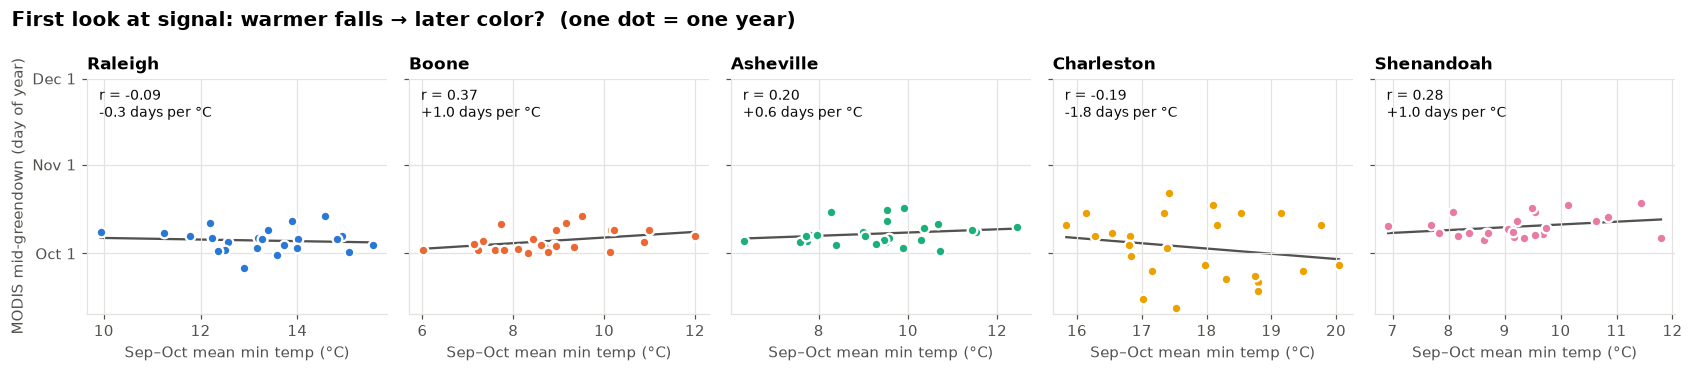

In [21]:
dfm = phen[phen["product"] == "MODIS"].merge(feat, on=["name", "year"])
n = len(REGION_ORDER)
fig, axes = plt.subplots(1, n, figsize=(3.1 * n, 3.4), sharey=True)
for ax, region in zip(np.atleast_1d(axes), REGION_ORDER):
    d = dfm[dfm["name"] == region].dropna(subset=["tmin_SepOct", "mid_greendown_p50"])
    ax.scatter(d["tmin_SepOct"], d["mid_greendown_p50"], s=40, color=REGION_COLORS[region],
               edgecolor="white", linewidth=1.5, zorder=2)
    if len(d) >= 5:
        slope, icpt = np.polyfit(d["tmin_SepOct"], d["mid_greendown_p50"], 1)
        xs = np.linspace(d["tmin_SepOct"].min(), d["tmin_SepOct"].max(), 10)
        ax.plot(xs, slope * xs + icpt, color=INK2, linewidth=1.5, zorder=1)
        r = np.corrcoef(d["tmin_SepOct"], d["mid_greendown_p50"])[0, 1]
        ax.text(0.04, 0.96, f"r = {r:.2f}\n{slope:+.1f} days per °C", transform=ax.transAxes,
                va="top", fontsize=9, color=INK)
    ax.set_title(region, loc="left")
    ax.set_xlabel("Sep–Oct mean min temp (°C)")
np.atleast_1d(axes)[0].set_ylabel("MODIS mid-greendown (day of year)")
month_axis(np.atleast_1d(axes)[0], "y", 250, 340)
fig.suptitle("First look at signal: warmer falls → later color?  (one dot = one year)",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
save(fig, "fig8_signal_preview")

In [22]:
regions_nc = study_regions.filter(ee.Filter.neq("name", "Charleston"))

# --- Elevation of FOREST pixels only (that's where the color is) ---
dem = ee.Image("USGS/SRTMGL1_003").select("elevation")
elev_reducer = (ee.Reducer.percentile([10, 50, 90], ["p10", "p50", "p90"])
                .combine(ee.Reducer.mean(), sharedInputs=True))
elev_df = fc_to_df(dem.updateMask(forest_mask).reduceRegions(
    collection=regions_nc, reducer=elev_reducer, scale=30, tileScale=8))
# single-band outputs are named p10/p50/p90/mean (or elevation_p10/... on some API versions)
rename = {}
for k, new in [("p10", "elev_p10_m"), ("p50", "elev_median_m"), ("p90", "elev_p90_m"), ("mean", "elev_mean_m")]:
    for cand in (k, f"elevation_{k}"):
        if cand in elev_df.columns:
            rename[cand] = new
elev_df = elev_df.rename(columns=rename)[["name"] + list(rename.values())]

# --- Land cover mix: share of each region's area in each NLCD class ---
cover = (nlcd.eq(41).rename("frac_deciduous")
         .addBands(nlcd.eq(42).rename("frac_evergreen"))
         .addBands(nlcd.eq(43).rename("frac_mixed"))
         .addBands(nlcd.eq(90).rename("frac_woody_wetland"))
         .addBands(nlcd.gte(21).And(nlcd.lte(24)).rename("frac_developed")))
cover_df = fc_to_df(cover.reduceRegions(collection=regions_nc, reducer=ee.Reducer.mean(),
                                        scale=30, tileScale=8))
cover_df = cover_df[["name", "frac_deciduous", "frac_evergreen", "frac_mixed",
                     "frac_woody_wetland", "frac_developed"]]
cover_df["frac_hardwood"] = cover_df["frac_deciduous"] + cover_df["frac_mixed"]
cover_df["hardwood_share_of_forest"] = cover_df["frac_hardwood"] / (
    cover_df["frac_hardwood"] + cover_df["frac_evergreen"])

# --- Site latitude / longitude (needed for day length) ---
loc_df = pd.DataFrame([{"name": n, "lon": c[0], "lat": c[1]} for n, c in locations.items()
                       if n != "Charleston"])

static = loc_df.merge(elev_df, on="name").merge(cover_df, on="name")
static.to_csv(f"{OUT_DIR}/static_features.csv", index=False)
static.round(3)

,name,lon,lat,elev_p10_m,elev_median_m,elev_p90_m,elev_mean_m,frac_deciduous,frac_evergreen,frac_mixed,frac_woody_wetland,frac_developed,frac_hardwood,hardwood_share_of_forest
0,Raleigh,-78.696,35.766,73.025,101.028,136.032,102.908,0.112,0.171,0.148,0.050,0.343,0.260,0.603
1,Boone,-81.685,36.218,491.489,931.491,1203.451,890.222,0.507,0.028,0.268,0.001,0.085,0.775,0.965
2,Asheville,-82.558,35.634,643.565,883.483,1235.499,911.477,0.534,0.016,0.166,0.001,0.158,0.700,0.978
3,Shenandoah,-78.407,38.499,339.542,563.504,875.425,587.666,0.791,0.018,0.128,0.000,0.028,0.919,0.980


In [23]:
import numpy as np
import pandas as pd

static = pd.read_csv(f"{OUT_DIR}/static_features.csv")
wx = pd.read_csv(f"{OUT_DIR}/weather_daily.csv", parse_dates=["date"])
wx = wx[wx["name"] != "Charleston"].copy()
wx["year"] = wx["date"].dt.year
wx["doy"] = wx["date"].dt.dayofyear
wx["md"] = wx["date"].dt.strftime("%m-%d")

pdsi_path = f"{OUT_DIR}/pdsi.csv"
pdsi = pd.read_csv(pdsi_path, parse_dates=["date"]) if os.path.exists(pdsi_path) else None


def win(df, start, end):
    """Rows between two MM-DD dates (inclusive)."""
    md = df["date"].dt.strftime("%m-%d")
    return df[(md >= start) & (md <= end)]


def agg(start, end, col, how):
    return win(wx, start, end).groupby(["name", "year"])[col].agg(how)


cdd = lambda d: (20 - d["tmean"]).clip(lower=0)      # cold degree-days below 20 °C

feat = pd.DataFrame({
    # temperature
    "tmax_Aug":            agg("08-01", "08-31", "tmax", "mean"),
    "tmin_Sep":            agg("09-01", "09-30", "tmin", "mean"),
    "tmin_SepOct":         agg("09-01", "10-31", "tmin", "mean"),
    "cdd_Sep":             win(wx, "09-01", "09-30").assign(c=cdd).groupby(["name", "year"])["c"].sum(),
    "cdd_Sep1_Oct15":      win(wx, "09-01", "10-15").assign(c=cdd).groupby(["name", "year"])["c"].sum(),
    "cold_nights_Sep1_Oct15": win(wx, "09-01", "10-15").assign(c=lambda d: d["tmin"] < 5)
                                .groupby(["name", "year"])["c"].sum(),
    # water
    "precip_AugSep":       agg("08-01", "09-30", "pr", "sum"),
    "precip_Oct":          agg("10-01", "10-31", "pr", "sum"),
    "vpd_AugSep":          agg("08-01", "09-30", "vpd", "mean"),
    # sunlight
    "srad_Sep":            agg("09-01", "09-30", "srad", "mean"),
    "srad_SepOct":         agg("09-01", "10-31", "srad", "mean"),
})
if pdsi is not None:
    pdsi = pdsi[pdsi["name"] != "Charleston"].copy()
    pdsi["year"] = pdsi["date"].dt.year
    feat["pdsi_AugSep"] = win(pdsi, "08-01", "09-30").groupby(["name", "year"])["pdsi"].mean()

# first fall frost: first day on/after Aug 1 with tmin <= 0 °C. If none by Nov 30, the
# frost came later than we can see -> fill with Dec 1 (335) and flag it as censored.
frost = (wx[(wx["md"] >= "08-01") & (wx["tmin"] <= 0)]
         .groupby(["name", "year"])["doy"].min())
feat["first_frost_doy"] = frost
feat = feat.reset_index()
feat["frost_censored"] = feat["first_frost_doy"].isna().astype(int)
feat["first_frost_doy"] = feat["first_frost_doy"].fillna(335)


# day length (hours) from latitude + day of year — Forsythe et al. (1995) CBM model
def day_length(lat, doy):
    theta = 0.2163108 + 2 * np.arctan(0.9671396 * np.tan(0.00860 * (doy - 186)))
    phi = np.arcsin(0.39795 * np.cos(theta))
    p = 0.8333
    x = (np.sin(np.radians(p)) + np.sin(np.radians(lat)) * np.sin(phi)) / (
        np.cos(np.radians(lat)) * np.cos(phi))
    return 24 - (24 / np.pi) * np.arccos(np.clip(x, -1, 1))


doys = np.arange(172, 366)
static["daylen_Oct1_h"] = static["lat"].apply(lambda la: day_length(la, 274))
static["doy_daylen_below_11h"] = static["lat"].apply(
    lambda la: int(doys[np.argmax(day_length(la, doys) < 11)]))

feat.round(2).head()

,name,year,tmax_Aug,tmin_Sep,tmin_SepOct,cdd_Sep,cdd_Sep1_Oct15,cold_nights_Sep1_Oct15,precip_AugSep,precip_Oct,vpd_AugSep,srad_Sep,srad_SepOct,pdsi_AugSep,first_frost_doy,frost_censored
0,Asheville,2001,27.21,9.94,6.33,117.73,230.94,13,189.72,32.08,0.51,200.14,190.77,-2.21,269.0,0
1,Asheville,2002,28.46,13.78,11.52,36.51,88.47,0,217.54,100.20,0.67,195.49,169.56,-3.98,291.0,0
2,Asheville,2003,27.28,10.61,7.74,95.59,211.51,8,263.65,61.09,0.47,217.54,188.68,3.98,276.0,0
3,Asheville,2004,25.43,12.32,10.72,72.45,150.70,1,549.84,46.18,0.52,200.74,187.16,1.33,310.0,0
4,Asheville,2005,27.23,12.12,9.52,42.06,83.31,0,194.85,66.35,0.62,225.27,197.08,3.50,297.0,0


In [24]:
phen = pd.read_csv(f"{OUT_DIR}/phenology_regions.csv")
phen = phen[phen["name"] != "Charleston"]

modis = phen[phen["product"] == "MODIS"][[
    "name", "ecoregion", "year",
    "mid_greendown_p50",            # TARGET
    "mid_greendown_p25", "mid_greendown_p75", "mid_greendown_count", "forest_px_count",
    "mid_greenup_p50", "senescence_p50", "dormancy_p50",
]].rename(columns={"mid_greendown_p50": "peak_doy"})
modis["qa_retention"] = modis["mid_greendown_count"] / modis["forest_px_count"]
modis["peak_spread_days"] = modis["mid_greendown_p75"] - modis["mid_greendown_p25"]

viirs = (phen[phen["product"] == "VIIRS"][["name", "year", "mid_greendown_p50"]]
         .rename(columns={"mid_greendown_p50": "peak_doy_viirs"}))

# Start from the weather table so 2026 (no satellite target yet) is kept as the forecast row
df = (feat.merge(modis, on=["name", "year"], how="left")
          .merge(viirs, on=["name", "year"], how="left")
          .merge(static, on="name", how="left"))
df["ecoregion"] = df.groupby("name")["ecoregion"].transform("first")

df["helene_2024"] = ((df["year"] == 2024) & df["name"].isin(["Asheville", "Boone"])).astype(int)
df["peak_date"] = (pd.to_datetime(df["year"].astype(str) + "-01-01")
                   + pd.to_timedelta(df["peak_doy"] - 1, unit="D")).dt.date
df = df.sort_values(["name", "year"]).reset_index(drop=True)

df.to_csv(f"{OUT_DIR}/model_df.csv", index=False)
print(f"model_df: {df.shape[0]} rows x {df.shape[1]} columns  |  regions: {sorted(df['name'].unique())}  "
      f"|  years: {df['year'].min()}-{df['year'].max()}")
print("Rows with a satellite target:", df["peak_doy"].notna().sum(),
      "| forecast rows (no target yet):", df.loc[df["peak_doy"].isna(), ["name", "year"]].values.tolist())
print("\nMissing values (non-zero only):")
na = df.isna().sum()
print(na[na > 0] if (na > 0).any() else "none")
df.head()

model_df: 104 rows x 45 columns  |  regions: ['Asheville', 'Boone', 'Raleigh', 'Shenandoah']  |  years: 2001-2026
Rows with a satellite target: 100 | forecast rows (no target yet): [['Asheville', 2026], ['Boone', 2026], ['Raleigh', 2026], ['Shenandoah', 2026]]

Missing values (non-zero only):
peak_doy                4
mid_greendown_p25       4
mid_greendown_p75       4
mid_greendown_count     4
forest_px_count         4
mid_greenup_p50         4
senescence_p50          4
dormancy_p50            4
qa_retention            4
peak_spread_days        4
peak_doy_viirs         52
peak_date               4
dtype: int64


,name,year,tmax_Aug,tmin_Sep,tmin_SepOct,cdd_Sep,cdd_Sep1_Oct15,cold_nights_Sep1_Oct15,precip_AugSep,precip_Oct,...,frac_evergreen,frac_mixed,frac_woody_wetland,frac_developed,frac_hardwood,hardwood_share_of_forest,daylen_Oct1_h,doy_daylen_below_11h,helene_2024,peak_date
0,Asheville,2001,27.208161,9.936228,6.332893,117.732627,230.937374,13,189.717095,32.084786,...,0.016103,0.165887,0.001238,0.157944,0.699969,0.977512,11.863111,298,0,2001-10-05
1,Asheville,2002,28.457300,13.777409,11.517329,36.509488,88.469720,0,217.544567,100.202625,...,0.016103,0.165887,0.001238,0.157944,0.699969,0.977512,11.863111,298,0,2002-10-08
2,Asheville,2003,27.281184,10.606523,7.742068,95.586589,211.507382,8,263.648028,61.088931,...,0.016103,0.165887,0.001238,0.157944,0.699969,0.977512,11.863111,298,0,2003-10-05
3,Asheville,2004,25.427033,12.316006,10.721398,72.449768,150.695747,1,549.843636,46.184652,...,0.016103,0.165887,0.001238,0.157944,0.699969,0.977512,11.863111,298,0,2004-10-01
4,Asheville,2005,27.229870,12.117966,9.524890,42.056640,83.314375,0,194.850240,66.347415,...,0.016103,0.165887,0.001238,0.157944,0.699969,0.977512,11.863111,298,0,2005-10-16
